In [260]:
import pandas as pd

# ระบุ Path ไฟล์ที่มีเว้นวรรคตรง 'Dataset 2'
file_path = '/content/A detailed dataset of motor insurance policies with coverage-specific financial information.csv'

# อ่านไฟล์ CSV
df2 = pd.read_csv(file_path)

# แสดงขนาดข้อมูล (แถว, คอลัมน์) และตัวอย่างข้อมูล 5 แถวแรก
df2.head()

,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,...,liability_property_incurred,liability_injury_incurred,property_incurred,theft_incurred,fire_incurred,glass_incurred,legal_protection_incurred,occupants_incurred,total_exposure,liability_exposure
0,1,2022,COMP_E,C,NB,A,G,48,22.0,26.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.09863,0.09863
1,2,2022,COMP_E,A,P,A,G,43,24.0,19.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
2,2,2023,COMP_E,A,P,A,G,44,25.0,19.0,...,233.013,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
3,2,2024,COMP_E,A,P,A,G,45,26.0,18.0,...,1035.000,0.0,1551.3615,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
4,3,2022,COMP_E,A,NB,S,G,45,26.0,19.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000


ตรวจสอบขนาดข้อมูล และ Data types

In [261]:
print("Rows:", df2.shape[0])
print("Columns:", df2.shape[1])

print("\nData types:")
print(df2.dtypes)

Rows: 354140
Columns: 47

Data types:
insured_id                       int64
year                             int64
policy_type                     object
policy_status                   object
business_type                   object
payment_frequency               object
bonus_score                     object
driver_age                       int64
vehicle_age                    float64
age_driving_licence            float64
fuel_type                       object
vehicle_value                  float64
seats                            int64
power_to_weight_ratio          float64
vehicle_brand                   object
municipality_type               object
circulation_area                object
total_premium                  float64
liability_premium              float64
property_damage_premium        float64
theft_premium                  float64
fire_premium                   float64
glass_premium                  float64
legal_protection_premium       float64
occupants_premium         

เปลี่ยน data type

*   vehicle_age
*   age_driving_licence




In [262]:
df2['vehicle_age'] = df2['vehicle_age'].astype('Int64')
df2['age_driving_licence'] = df2['age_driving_licence'].astype('Int64')

# ตรวจสอบ Data types
print(df2[['vehicle_age', 'age_driving_licence']].dtypes)

vehicle_age            Int64
age_driving_licence    Int64
dtype: object


ตรวจสอบจำนวนค่าที่เป็น duplicated

In [263]:
df2.duplicated().sum()

np.int64(0)

ตรวจสอบ Missing value

In [264]:
# จำนวน Missing
missing_count = df2.isnull().sum()

# เปอร์เซ็นต์ Missing
missing_percent = (df2.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percent': missing_percent
})

# แสดงเฉพาะตัวแปรที่มี Missing
missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
].sort_values('Missing_Count', ascending=False)

missing_summary

,Missing_Count,Missing_Percent
fuel_type,1287,0.36
vehicle_value,513,0.14
age_driving_licence,2,0.00
vehicle_age,2,0.00


ลบแถวที่ Missing value เนื่องจากมี Missing value ที่ต่ำกว่า 10% ของข้อมูลทั้งหมด

In [265]:
df2 = df2.dropna(subset=['fuel_type', 'vehicle_value', 'age_driving_licence', 'vehicle_age']).copy()

df2.shape

(352338, 47)

In [266]:
df2[['fuel_type', 'vehicle_value', 'age_driving_licence', 'vehicle_age']].isna().sum()

,0
fuel_type,0
vehicle_value,0
age_driving_licence,0
vehicle_age,0


ตรวจสอบจำนวน Observation จาก ID

In [267]:
duplicate_ids = df2['insured_id'].duplicated().sum()
print("Duplicated ID records:", duplicate_ids)

Duplicated ID records: 167614


In [268]:
print("Rows:", len(df2))

print("Unique insured_id:", df2["insured_id"].nunique())

print("Total insured_id values:", len(df2["insured_id"]))

print("Duplicated insured_id:", df2["insured_id"].duplicated().sum())

Rows: 352338
Unique insured_id: 184724
Total insured_id values: 352338
Duplicated insured_id: 167614


ตรวจสอบค่าติดลบ

In [269]:
numeric_cols = df2.select_dtypes(include='number').columns

(df2[numeric_cols] < 0).sum()

,0
insured_id,0
year,0
driver_age,0
vehicle_age,0
age_driving_licence,0
vehicle_value,0
seats,0
power_to_weight_ratio,0
total_premium,0
liability_premium,0




---



ตรวจสอบค่าผิดปกติ

*   อายุคนขับต่ำกว่า 18
*   Exposure อยู่นอกช่วง 0–1







In [270]:
print((df2['driver_age'] < 18).sum())
print((~df2['total_exposure'].between(0, 1)).sum())

0
0




---



# After EDA


# Feature Engineering

In [271]:
df2.head()

,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,...,liability_property_incurred,liability_injury_incurred,property_incurred,theft_incurred,fire_incurred,glass_incurred,legal_protection_incurred,occupants_incurred,total_exposure,liability_exposure
0,1,2022,COMP_E,C,NB,A,G,48,22,26,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.09863,0.09863
1,2,2022,COMP_E,A,P,A,G,43,24,19,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
2,2,2023,COMP_E,A,P,A,G,44,25,19,...,233.013,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
3,2,2024,COMP_E,A,P,A,G,45,26,18,...,1035.000,0.0,1551.3615,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
4,3,2022,COMP_E,A,NB,S,G,45,26,19,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000


ลบข้อมูลของรถแบนด์ต่างๆที่มีจำนวนแถวน้อยกว่า 100 แถว เนื่องจากจะทำให้มีฟีเจอร์เยอะมากเกินไปในการทำ enconding  
LADA               79  
DAIHATSU           50  
INFINITI           29  
ISUZU              23  
ABARTH             20  
SANTANA            17  
HUMMER             15  
AIXAM               9  
MICROCAR            7  
FERRARI             5  
MASERATI            4  
HURTAN              4  
SIMCA               3  
GRECAV              3    
ASTON MARTIN        3  
GMC                 3  
ASIA MOTORS         1

In [272]:
print("Number of vehicle brands:", df2["vehicle_brand"].nunique())

print(
    df2["vehicle_brand"]
    .value_counts()
)

Number of vehicle brands: 67
vehicle_brand
RENAULT        34311
CITROEN        32476
PEUGEOT        29519
VOLKSWAGEN     28774
FORD           28231
               ...  
PIAGGIO            3
MG                 2
ASIA MOTORS        2
BENTLEY            1
GME                1
Name: count, Length: 67, dtype: int64


In [273]:
brands_to_remove = [
    "LADA",
    "DAIHATSU",
    "INFINITI",
    "ISUZU",
    "ABARTH",
    "SANTANA",
    "HUMMER",
    "AIXAM",
    "MICROCAR",
    "FERRARI",
    "MASERATI",
    "HURTAN",
    "SIMCA",
    "GRECAV",
    "ASTON MARTIN",
    "GMC",
    "ASIA MOTORS"
]

df2 = df2[
    ~df2["vehicle_brand"].isin(brands_to_remove)
].copy()

In [274]:
print(
    df2[df2["vehicle_brand"].isin(brands_to_remove)]["vehicle_brand"]
    .value_counts()
)

Series([], Name: count, dtype: int64)


In [275]:
df2.shape

(351977, 47)



---



# Risk score

สร้างฟีเจอร์การเคลม

*   0 ไม่มีการเคลม
*   1 มีการเคลม



In [276]:
df2["claim"] = (df2["total_claims"] > 0).astype(int)

In [277]:
# # ดูหัวตาราง 5-10 แถวแรก
# df2[["total_claims", "claim"]].head(5)

# หรือสุ่มดูแถวที่มี claim เป็น 0 และ 1
df2[["total_claims", "claim"]].sample(5)

,total_claims,claim
277674,0,0
345844,0,0
197387,0,0
66372,0,0
73465,1,1


ลบคอลัมน์ที่เป็นข้อมูลหลังการทำกรมธรรม์

In [278]:
drop_cols = [
    # กลุ่ม Premium
    'total_premium', 'liability_premium', 'property_damage_premium',
    'theft_premium', 'fire_premium', 'glass_premium',
    'legal_protection_premium', 'occupants_premium',

    # กลุ่ม Claims
    'total_claims', 'liability_claims', 'liability_property_claims',
    'liability_injury_claims', 'property_claims', 'theft_claims',
    'fire_claims', 'glass_claims', 'legal_protection_claims', 'occupants_claims',

    # กลุ่ม Incurred
    'total_incurred', 'liability_incurred', 'liability_property_incurred',
    'liability_injury_incurred', 'property_incurred', 'theft_incurred',
    'fire_incurred', 'glass_incurred', 'legal_protection_incurred', 'occupants_incurred',

    # กลุ่ม Exposure
    'total_exposure', 'liability_exposure'
]

df2 = df2.drop(columns=drop_cols, errors='ignore')

In [279]:
# df2.shape
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 351977 entries, 0 to 354139
Data columns (total 18 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   insured_id             351977 non-null  int64  
 1   year                   351977 non-null  int64  
 2   policy_type            351977 non-null  object 
 3   policy_status          351977 non-null  object 
 4   business_type          351977 non-null  object 
 5   payment_frequency      351977 non-null  object 
 6   bonus_score            351977 non-null  object 
 7   driver_age             351977 non-null  int64  
 8   vehicle_age            351977 non-null  Int64  
 9   age_driving_licence    351977 non-null  Int64  
 10  fuel_type              351977 non-null  object 
 11  vehicle_value          351977 non-null  float64
 12  seats                  351977 non-null  int64  
 13  power_to_weight_ratio  351977 non-null  float64
 14  vehicle_brand          351977 non-null  o

In [280]:
df2.head()


,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,fuel_type,vehicle_value,seats,power_to_weight_ratio,vehicle_brand,municipality_type,circulation_area,claim
0,1,2022,COMP_E,C,NB,A,G,48,22,26,G,149511.4425,4,3.92,PORSCHE,I,U,0
1,2,2022,COMP_E,A,P,A,G,43,24,19,D,65065.1232,8,10.15,MERCEDES,I,U,0
2,2,2023,COMP_E,A,P,A,G,44,25,19,D,65065.1232,8,10.15,MERCEDES,I,U,1
3,2,2024,COMP_E,A,P,A,G,45,26,18,D,65065.1232,8,10.15,MERCEDES,I,U,1
4,3,2022,COMP_E,A,NB,S,G,45,26,19,D,51626.6625,7,9.19,KIA,I,R,0


เช็ค unique id

In [281]:
print("Rows:", len(df2))

print("Unique insured_id:", df2["insured_id"].nunique())

print("Total insured_id values:", len(df2["insured_id"]))

print("Duplicated insured_id:", df2["insured_id"].duplicated().sum())

Rows: 351977
Unique insured_id: 184544
Total insured_id values: 351977
Duplicated insured_id: 167433


แบ่งข้อมูล

In [282]:
y = df2["claim"]

X = df2.drop(columns=[
    "claim",
    "insured_id"
])

In [283]:
from sklearn.model_selection import train_test_split

# =========================
# 1. Define Target & Features
# =========================

# Target: Claim / No Claim
y = df2["claim"]

# Features
# ตัดทั้ง target และ total_claims ออก
X = df2.drop(columns=["claim"])


# =========================
# 2. Split 70:30
# =========================

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)


# =========================
# 3. Split 80:20
# =========================

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# =========================
# 4. Check sizes
# =========================

print("===== 70:30 Split =====")
print("Train:", X_train_70.shape)
print("Test :", X_test_70.shape)

print("\n===== 80:20 Split =====")
print("Train:", X_train_80.shape)
print("Test :", X_test_80.shape)

===== 70:30 Split =====
Train: (246383, 17)
Test : (105594, 17)

===== 80:20 Split =====
Train: (281581, 17)
Test : (70396, 17)


In [284]:
print("===== Overall =====")
print(y.value_counts(normalize=True))

print("\n===== 70:30 =====")
print("Train:")
print(y_train_70.value_counts(normalize=True))
print("Test:")
print(y_test_70.value_counts(normalize=True))

print("\n===== 80:20 =====")
print("Train:")
print(y_train_80.value_counts(normalize=True))
print("Test:")
print(y_test_80.value_counts(normalize=True))

===== Overall =====
claim
0    0.856684
1    0.143316
Name: proportion, dtype: float64

===== 70:30 =====
Train:
claim
0    0.856682
1    0.143318
Name: proportion, dtype: float64
Test:
claim
0    0.856687
1    0.143313
Name: proportion, dtype: float64

===== 80:20 =====
Train:
claim
0    0.856684
1    0.143316
Name: proportion, dtype: float64
Test:
claim
0    0.856682
1    0.143318
Name: proportion, dtype: float64


# Encoding

In [290]:
# ============================================
# 1. กำหนดประเภทตัวแปร
# ============================================

categorical_cols = [
    "year",
    "business_type",
    "payment_frequency",
    "fuel_type",
    "vehicle_brand",
    "municipality_type",
    "circulation_area",
    "policy_status"
]

ordinal_cols = [
    "bonus_score"
]

numeric_cols = [
    "driver_age",
    "vehicle_age",
    "age_driving_licence",
    "vehicle_value",
    "seats",
    "power_to_weight_ratio"
]


# ============================================
# 2. Import
# ============================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder


# ============================================
# 3. Function สำหรับสร้าง Encoder
# ============================================

def create_encoder():

    # Categorical → Imputation + One-Hot Encoding
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ))
    ])

    # Ordinal → Imputation + Ordinal Encoding
    ordinal_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ordinal", OrdinalEncoder(
            categories=[["B", "N", "G"]],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])

    # Numeric → Imputation อย่างเดียว
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    encoder = ColumnTransformer(
        transformers=[
            ("categorical", categorical_pipeline, categorical_cols),
            ("ordinal", ordinal_pipeline, ordinal_cols),
            ("numeric", numeric_pipeline, numeric_cols)
        ]
    )

    return encoder


# ============================================
# 4. Encoding สำหรับ 70:30
# ============================================

encoder_70 = create_encoder()

# Fit เฉพาะ Training set
X_train_70_encoded = encoder_70.fit_transform(X_train_70)

# Test ใช้ transform อย่างเดียว
X_test_70_encoded = encoder_70.transform(X_test_70)

# ชื่อ Features หลัง Encoding
feature_names_70 = encoder_70.get_feature_names_out()


# ============================================
# 5. Encoding สำหรับ 80:20
# ============================================

encoder_80 = create_encoder()

# Fit เฉพาะ Training set
X_train_80_encoded = encoder_80.fit_transform(X_train_80)

# Test ใช้ transform อย่างเดียว
X_test_80_encoded = encoder_80.transform(X_test_80)

# ชื่อ Features หลัง Encoding
feature_names_80 = encoder_80.get_feature_names_out()


# ============================================
# 6. ดูจำนวน Features หลัง Encoding
# ============================================

print("===== 70:30 =====")
print("Training shape:", X_train_70_encoded.shape)
print("Test shape:", X_test_70_encoded.shape)
print("Number of features:", len(feature_names_70))

print("\n===== 80:20 =====")
print("Training shape:", X_train_80_encoded.shape)
print("Test shape:", X_test_80_encoded.shape)
print("Number of features:", len(feature_names_80))


# ============================================
# 7. ดูชื่อ Columns หลัง Encoding
# ============================================

print("\n===== Features 70:30 =====")
for i, col in enumerate(feature_names_70):
    print(i, col)

print("\n===== Features 80:20 =====")
for i, col in enumerate(feature_names_80):
    print(i, col)

===== 70:30 =====
Training shape: (246383, 72)
Test shape: (105594, 72)
Number of features: 72

===== 80:20 =====
Training shape: (281581, 73)
Test shape: (70396, 73)
Number of features: 73

===== Features 70:30 =====
0 categorical__year_2022
1 categorical__year_2023
2 categorical__year_2024
3 categorical__business_type_NB
4 categorical__business_type_P
5 categorical__payment_frequency_A
6 categorical__payment_frequency_Q
7 categorical__payment_frequency_S
8 categorical__fuel_type_D
9 categorical__fuel_type_G
10 categorical__vehicle_brand_ALFA ROMEO
11 categorical__vehicle_brand_AUDI
12 categorical__vehicle_brand_BENTLEY
13 categorical__vehicle_brand_BMW
14 categorical__vehicle_brand_CHEVROLET
15 categorical__vehicle_brand_CHRYSLER
16 categorical__vehicle_brand_CITROEN
17 categorical__vehicle_brand_DACIA
18 categorical__vehicle_brand_DAEWOO
19 categorical__vehicle_brand_DAF
20 categorical__vehicle_brand_DODGE
21 categorical__vehicle_brand_FIAT
22 categorical__vehicle_brand_FORD
23 cate

In [291]:
# ดู 10 แถวแรกของ 70:30
X_train_70_preview = pd.DataFrame(
    X_train_70_encoded[:10].toarray(),
    columns=feature_names_70
)

display(X_train_70_preview)

,categorical__year_2022,categorical__year_2023,categorical__year_2024,categorical__business_type_NB,categorical__business_type_P,categorical__payment_frequency_A,categorical__payment_frequency_Q,categorical__payment_frequency_S,categorical__fuel_type_D,categorical__fuel_type_G,...,categorical__circulation_area_U,categorical__policy_status_A,categorical__policy_status_C,ordinal__bonus_score,numeric__driver_age,numeric__vehicle_age,numeric__age_driving_licence,numeric__vehicle_value,numeric__seats,numeric__power_to_weight_ratio
0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,2.0,59.0,35.0,24.0,29523.37500,5.0,10.92
1,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,2.0,44.0,24.0,19.0,17774.40000,5.0,13.89
2,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,2.0,37.0,14.0,23.0,16373.66378,5.0,11.89
3,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,1.0,2.0,53.0,20.0,32.0,55653.67500,5.0,12.93
4,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,2.0,65.0,43.0,22.0,26625.37500,5.0,11.03
5,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,2.0,30.0,11.0,19.0,33399.45000,5.0,10.98
6,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,2.0,37.0,19.0,18.0,45770.43240,5.0,8.88
7,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,1.0,1.0,0.0,2.0,56.0,35.0,21.0,32759.47500,5.0,12.05
8,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,...,1.0,1.0,0.0,2.0,65.0,31.0,34.0,15595.76813,5.0,10.20
9,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,2.0,44.0,21.0,23.0,30429.00000,7.0,14.29


# standard scale

In [298]:
from sklearn.preprocessing import StandardScaler

# ============================================
# Standard Scaling — 70:30
# ============================================

scaler_70 = StandardScaler(with_mean=False)

# Fit เฉพาะ Training set
X_train_70_scaled = scaler_70.fit_transform(
    X_train_70_encoded
)

# Test ใช้ transform อย่างเดียว
X_test_70_scaled = scaler_70.transform(
    X_test_70_encoded
)


# ============================================
# Standard Scaling — 80:20
# ============================================

scaler_80 = StandardScaler(with_mean=False)

# Fit เฉพาะ Training set
X_train_80_scaled = scaler_80.fit_transform(
    X_train_80_encoded
)

# Test ใช้ transform อย่างเดียว
X_test_80_scaled = scaler_80.transform(
    X_test_80_encoded
)

In [301]:
import numpy as np

# ============================================
# 70:30
# ============================================

mean_70 = np.asarray(X_train_70_scaled.mean(axis=0)).ravel()

std_70 = np.sqrt(
    np.asarray(X_train_70_scaled.multiply(X_train_70_scaled).mean(axis=0)).ravel()
    - mean_70**2
)

stats_70 = pd.DataFrame({
    "Feature": feature_names_70,
    "Mean": mean_70,
    "Std": std_70
})

display(stats_70)

,Feature,Mean,Std
0,categorical__year_2022,0.482809,1.0
1,categorical__year_2023,0.710631,1.0
2,categorical__year_2024,0.951980,1.0
3,categorical__business_type_NB,1.501633,1.0
4,categorical__business_type_P,0.665942,1.0
...,...,...,...
67,numeric__vehicle_age,2.229208,1.0
68,numeric__age_driving_licence,3.611116,1.0
69,numeric__vehicle_value,2.205943,1.0
70,numeric__seats,6.743777,1.0


In [302]:
# ============================================
# 80:20
# ============================================

mean_80 = np.asarray(X_train_80_scaled.mean(axis=0)).ravel()

std_80 = np.sqrt(
    np.asarray(X_train_80_scaled.multiply(X_train_80_scaled).mean(axis=0)).ravel()
    - mean_80**2
)

stats_80 = pd.DataFrame({
    "Feature": feature_names_80,
    "Mean": mean_80,
    "Std": std_80
})

display(stats_80)

,Feature,Mean,Std
0,categorical__year_2022,0.483823,1.0
1,categorical__year_2023,0.710752,1.0
2,categorical__year_2024,0.950608,1.0
3,categorical__business_type_NB,1.502609,1.0
4,categorical__business_type_P,0.665509,1.0
...,...,...,...
68,numeric__vehicle_age,2.229900,1.0
69,numeric__age_driving_licence,3.614832,1.0
70,numeric__vehicle_value,2.205394,1.0
71,numeric__seats,6.740711,1.0


เทรน XGBoot

In [303]:
from xgboost import XGBClassifier

xgb_70 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_70.fit(
    X_train_70_encoded,
    y_train_70
)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

In [304]:
# ============================================
# XGBoost — 80:20
# ============================================

from xgboost import XGBClassifier

xgb_80 = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

# Train
xgb_80.fit(
    X_train_80_encoded,
    y_train_80
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=None,
              num_parallel_tree=None, ...)

logistic

In [305]:
from sklearn.linear_model import LogisticRegression

# ============================================
# Logistic Regression — 70:30
# ============================================

lr_70 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_70.fit(
    X_train_70_scaled,
    y_train_70
)


# ============================================
# Logistic Regression — 80:20
# ============================================

lr_80 = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_80.fit(
    X_train_80_scaled,
    y_train_80
)

LogisticRegression(max_iter=1000, random_state=42)

In [308]:
# ============================================================
# 1. Predict + Predict Probability
# ============================================================

# ---------- XGBoost 70:30 ----------
y_pred_xgb_70 = xgb_70.predict(X_test_70_encoded)
y_prob_xgb_70 = xgb_70.predict_proba(X_test_70_encoded)[:, 1]


# ---------- XGBoost 80:20 ----------
y_pred_xgb_80 = xgb_80.predict(X_test_80_encoded)
y_prob_xgb_80 = xgb_80.predict_proba(X_test_80_encoded)[:, 1]


# ---------- Logistic Regression 70:30 ----------
y_pred_lr_70 = lr_70.predict(X_test_70_scaled)
y_prob_lr_70 = lr_70.predict_proba(X_test_70_scaled)[:, 1]


# ---------- Logistic Regression 80:20 ----------
y_pred_lr_80 = lr_80.predict(X_test_80_scaled)
y_prob_lr_80 = lr_80.predict_proba(X_test_80_scaled)[:, 1]

In [310]:
# ============================================================
# 1. Import Metrics
# ============================================================

import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# ============================================================
# 2. Predict + Probability ของทั้ง 4 โมเดล
# ============================================================

# XGBoost 70:30
y_pred_xgb_70 = xgb_70.predict(X_test_70_encoded)
y_prob_xgb_70 = xgb_70.predict_proba(X_test_70_encoded)[:, 1]

# XGBoost 80:20
y_pred_xgb_80 = xgb_80.predict(X_test_80_encoded)
y_prob_xgb_80 = xgb_80.predict_proba(X_test_80_encoded)[:, 1]

# Logistic Regression 70:30
y_pred_lr_70 = lr_70.predict(X_test_70_scaled)
y_prob_lr_70 = lr_70.predict_proba(X_test_70_scaled)[:, 1]

# Logistic Regression 80:20
y_pred_lr_80 = lr_80.predict(X_test_80_scaled)
y_prob_lr_80 = lr_80.predict_proba(X_test_80_scaled)[:, 1]


# ============================================================
# 3. Function สำหรับประเมิน Model
# ============================================================

def evaluate_model(y_true, y_pred, y_prob):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred
    ).ravel()

    return {
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Brier Score": brier_score_loss(y_true, y_prob),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


# ============================================================
# 4. Evaluate ทั้ง 4 Models
# ============================================================

results_xgb_70 = evaluate_model(
    y_test_70,
    y_pred_xgb_70,
    y_prob_xgb_70
)

results_xgb_80 = evaluate_model(
    y_test_80,
    y_pred_xgb_80,
    y_prob_xgb_80
)

results_lr_70 = evaluate_model(
    y_test_70,
    y_pred_lr_70,
    y_prob_lr_70
)

results_lr_80 = evaluate_model(
    y_test_80,
    y_pred_lr_80,
    y_prob_lr_80
)


# ============================================================
# 5. ตารางเปรียบเทียบ
# ============================================================

comparison = pd.DataFrame(
    [
        results_xgb_70,
        results_xgb_80,
        results_lr_70,
        results_lr_80
    ],
    index=[
        "XGBoost 70:30",
        "XGBoost 80:20",
        "Logistic Regression 70:30",
        "Logistic Regression 80:20"
    ]
)

display(comparison.round(4))

,ROC-AUC,PR-AUC,Brier Score,Precision,Recall,F1,TN,FP,FN,TP
XGBoost 70:30,0.6055,0.2060,0.1205,0.4557,0.0024,0.0047,90418,43,15097,36
XGBoost 80:20,0.6062,0.2060,0.1204,0.4043,0.0019,0.0037,60279,28,10070,19
Logistic Regression 70:30,0.5980,0.1982,0.1208,0.0000,0.0000,0.0000,90459,2,15133,0
Logistic Regression 80:20,0.5980,0.1981,0.1208,0.0000,0.0000,0.0000,60306,1,10089,0


In [311]:
print("LR 70:30")
print("Min:", y_prob_lr_70.min())
print("Max:", y_prob_lr_70.max())
print("Mean:", y_prob_lr_70.mean())

print("\nLR 80:20")
print("Min:", y_prob_lr_80.min())
print("Max:", y_prob_lr_80.max())
print("Mean:", y_prob_lr_80.mean())

LR 70:30
Min: 0.0029805112972699915
Max: 0.5596469356779578
Mean: 0.14330242329720924

LR 80:20
Min: 0.002926176506511143
Max: 0.530239280153676
Mean: 0.14323802781055942


In [312]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

for t in thresholds:
    print(
        f"Threshold {t}:",
        (y_prob_lr_70 >= t).sum()
    )

Threshold 0.1: 88215
Threshold 0.2: 12735
Threshold 0.3: 592
Threshold 0.4: 52
Threshold 0.5: 2


In [314]:
print(df2["claim"].value_counts())
print(df2["claim"].value_counts(normalize=True))

claim
0    301533
1     50444
Name: count, dtype: int64
claim
0    0.856684
1    0.143316
Name: proportion, dtype: float64


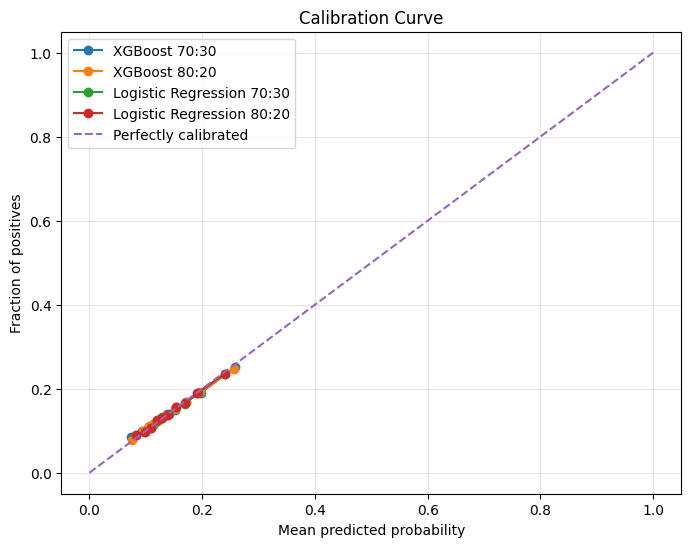

In [315]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

# XGBoost 70:30
prob_true_xgb_70, prob_pred_xgb_70 = calibration_curve(
    y_test_70,
    y_prob_xgb_70,
    n_bins=10,
    strategy="quantile"
)

# XGBoost 80:20
prob_true_xgb_80, prob_pred_xgb_80 = calibration_curve(
    y_test_80,
    y_prob_xgb_80,
    n_bins=10,
    strategy="quantile"
)

# Logistic Regression 70:30
prob_true_lr_70, prob_pred_lr_70 = calibration_curve(
    y_test_70,
    y_prob_lr_70,
    n_bins=10,
    strategy="quantile"
)

# Logistic Regression 80:20
prob_true_lr_80, prob_pred_lr_80 = calibration_curve(
    y_test_80,
    y_prob_lr_80,
    n_bins=10,
    strategy="quantile"
)

# Plot
plt.plot(
    prob_pred_xgb_70,
    prob_true_xgb_70,
    marker="o",
    label="XGBoost 70:30"
)

plt.plot(
    prob_pred_xgb_80,
    prob_true_xgb_80,
    marker="o",
    label="XGBoost 80:20"
)

plt.plot(
    prob_pred_lr_70,
    prob_true_lr_70,
    marker="o",
    label="Logistic Regression 70:30"
)

plt.plot(
    prob_pred_lr_80,
    prob_true_lr_80,
    marker="o",
    label="Logistic Regression 80:20"
)

# Perfect calibration
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfectly calibrated"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Fraction of positives")
plt.title("Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# สรุปการเลือกโมเดลสำหรับ Insurance Risk Score  

เปรียบเทียบจากตัวประเมินหลัก 3 ตัว ได้แก่ ROC-AUC, PR-AUC และ Brier Score  

*   ROC-AUC: XGBoost 80:20 = 0.6062 สูงกว่า Logistic Regression = 0.5980
*   PR-AUC: XGBoost 80:20 = 0.2060 สูงกว่า Logistic Regression = 0.1981
*   Brier Score: XGBoost 80:20 = 0.1204 ต่ำกว่า Logistic Regression = 0.1208 โดยค่าที่ต่ำกว่าดีกว่า

ดังนั้น XGBoost 80:20 ให้ผลดีที่สุดในทั้ง 3 ตัวประเมินหลัก จึงเลือก XGBoost 80:20 สำหรับสร้าง Insurance Risk Score โดยใช้ค่า predict_proba()[:,1] หรือ predicted probability of claim เป็น Risk Score ของลูกค้าแต่ละราย



---



# สร้าง Risk Score จาก XGBoost 80:20

In [317]:
# Transform ข้อมูลทั้งหมดด้วย encoder ที่ fit จาก training set
X_all_encoded = encoder_80.transform(X)

# สร้าง Risk Score จาก XGBoost
risk_score = xgb_80.predict_proba(X_all_encoded)[:, 1]

# เพิ่ม Risk Score เข้า DataFrame
df2["insurance_risk_score"] = risk_score

In [318]:
df2[[
    "insured_id",
    "claim",
    "insurance_risk_score"
]].head()

,insured_id,claim,insurance_risk_score
0,1,0,0.162202
1,2,0,0.336861
2,2,1,0.331023
3,2,1,0.333678
4,3,0,0.151353


In [319]:
df2.head()

,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,fuel_type,vehicle_value,seats,power_to_weight_ratio,vehicle_brand,municipality_type,circulation_area,claim,insurance_risk_score
0,1,2022,COMP_E,C,NB,A,G,48,22,26,G,149511.4425,4,3.92,PORSCHE,I,U,0,0.162202
1,2,2022,COMP_E,A,P,A,G,43,24,19,D,65065.1232,8,10.15,MERCEDES,I,U,0,0.336861
2,2,2023,COMP_E,A,P,A,G,44,25,19,D,65065.1232,8,10.15,MERCEDES,I,U,1,0.331023
3,2,2024,COMP_E,A,P,A,G,45,26,18,D,65065.1232,8,10.15,MERCEDES,I,U,1,0.333678
4,3,2022,COMP_E,A,NB,S,G,45,26,19,D,51626.6625,7,9.19,KIA,I,R,0,0.151353


In [321]:
print(df2["insurance_risk_score"].describe())

count    351977.000000
mean          0.143248
std           0.054255
min           0.018184
25%           0.105283
50%           0.131192
75%           0.170800
max           0.783237
Name: insurance_risk_score, dtype: float64




---



สร้างฟีเจอร์ใหม่ 2 ฟีเจอร์ ได้แก้


1.   driving_experience เพื่อสะท้อนประสบการณ์การขับขี่ของผู้เอาประกัน
2.   driver_age_group เพื่อสะท้อนลักษณะของผู้เอาประกันในแต่ละช่วงอายุ  โดยมีช่วงอายุดังนี้  

*   18-24
*   25-34
*   35-44
*   45-54
*   55-64
*   65+
    




In [ ]:
# # 1. Driving Experience
# df2["driving_experience"] = (
#     df2["driver_age"] - df2["age_driving_licence"]
# )

# # 2. Driver Age Group
# bins = [18, 25, 35, 45, 55, 65, float("inf")]
# labels = [
#     "18-24",
#     "25-34",
#     "35-44",
#     "45-54",
#     "55-64",
#     "65+"
# ]

# df2["driver_age_group"] = pd.cut(
#     df2["driver_age"],
#     bins=bins,
#     labels=labels,
#     right=False
# )

# # ตรวจสอบผลลัพธ์
# print(df2[[
#     "driver_age",
#     "age_driving_licence",
#     "driving_experience",
#     "driver_age_group"
# ]].head())

# print("\nDriver Age Group:")
# print(df2["driver_age_group"].value_counts().sort_index())

In [ ]:
df2.head()

เช็คว่าลบหมดมั้ย